
# Smart Fall Risk Detection Using Machine Learning

## Project Objective
To classify fall risk into three categories:
- Decision 0: Low Risk
- Decision 1: Medium Risk
- Decision 2: High Risk

## Dataset
cStick.csv


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [5]:
import os
print(os.getcwd())

C:\Users\nashv\Documents\smart_fall_risk_project


In [7]:
df = pd.read_csv(r"C:\Users\nashv\Documents\smart_fall_risk_project\data\cStick.csv")
df.head()

,Distance,Pressure,HRV,Sugar level,SpO2,Accelerometer,Decision
0,25.540,1.0,101.396,61.080,87.770,1.0,1
1,2.595,2.0,110.190,20.207,65.190,1.0,2
2,68.067,0.0,87.412,79.345,99.345,0.0,0
3,13.090,1.0,92.266,36.180,81.545,1.0,1
4,69.430,0.0,89.480,80.000,99.990,0.0,0


In [10]:
df.columns = df.columns.str.strip()
df.columns

Index(['Distance', 'Pressure', 'HRV', 'Sugar level', 'SpO2', 'Accelerometer',
       'Decision'],
      dtype='str')

In [11]:
df.shape

(2039, 7)

In [12]:
df.isnull().sum()

Distance         0
Pressure         0
HRV              0
Sugar level      0
SpO2             0
Accelerometer    0
Decision         0
dtype: int64

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2039 entries, 0 to 2038
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Distance       2039 non-null   float64
 1   Pressure       2039 non-null   float64
 2   HRV            2039 non-null   float64
 3   Sugar level    2039 non-null   float64
 4   SpO2           2039 non-null   float64
 5   Accelerometer  2039 non-null   float64
 6   Decision       2039 non-null   int64  
dtypes: float64(6), int64(1)
memory usage: 111.6 KB


In [14]:
df["Decision"].value_counts().sort_index()

Decision
0    690
1    682
2    667
Name: count, dtype: int64

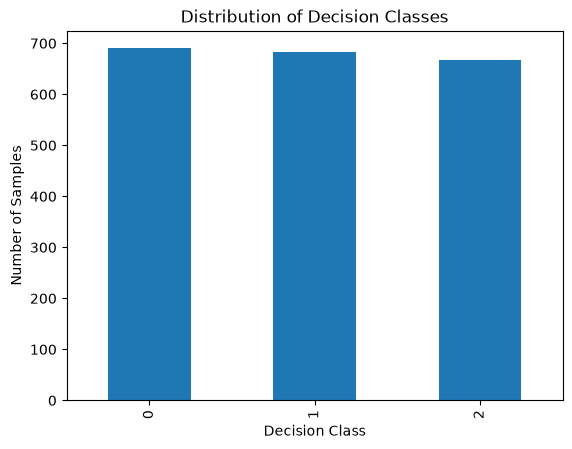

In [15]:
df["Decision"].value_counts().sort_index().plot(
    kind="bar",
    xlabel="Decision Class",
    ylabel="Number of Samples",
    title="Distribution of Decision Classes"
)

plt.show()

In [16]:
X = df.drop("Decision", axis=1)
y = df["Decision"]

In [17]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (2039, 6)
Target shape: (2039,)


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [19]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (1631, 6)
Testing features: (408, 6)
Training targets: (1631,)
Testing targets: (408,)


In [20]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [21]:
from sklearn.metrics import accuracy_score

y_pred = dt_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Decision Tree Accuracy:", accuracy * 100, "%")

Decision Tree Accuracy: 99.75490196078431 %


In [22]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       138
           1       0.99      1.00      1.00       137
           2       1.00      0.99      1.00       133

    accuracy                           1.00       408
   macro avg       1.00      1.00      1.00       408
weighted avg       1.00      1.00      1.00       408



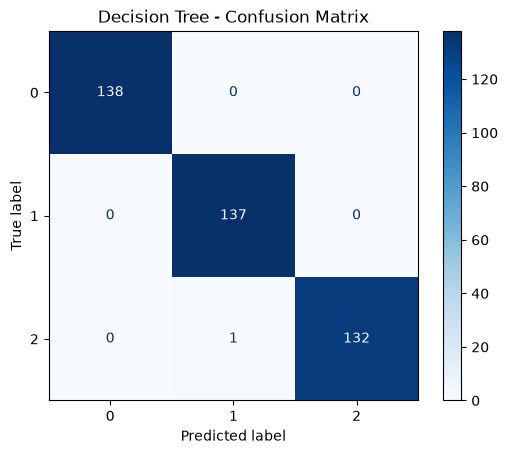

In [23]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1, 2]
)

disp.plot(cmap="Blues")
plt.title("Decision Tree - Confusion Matrix")
plt.show()

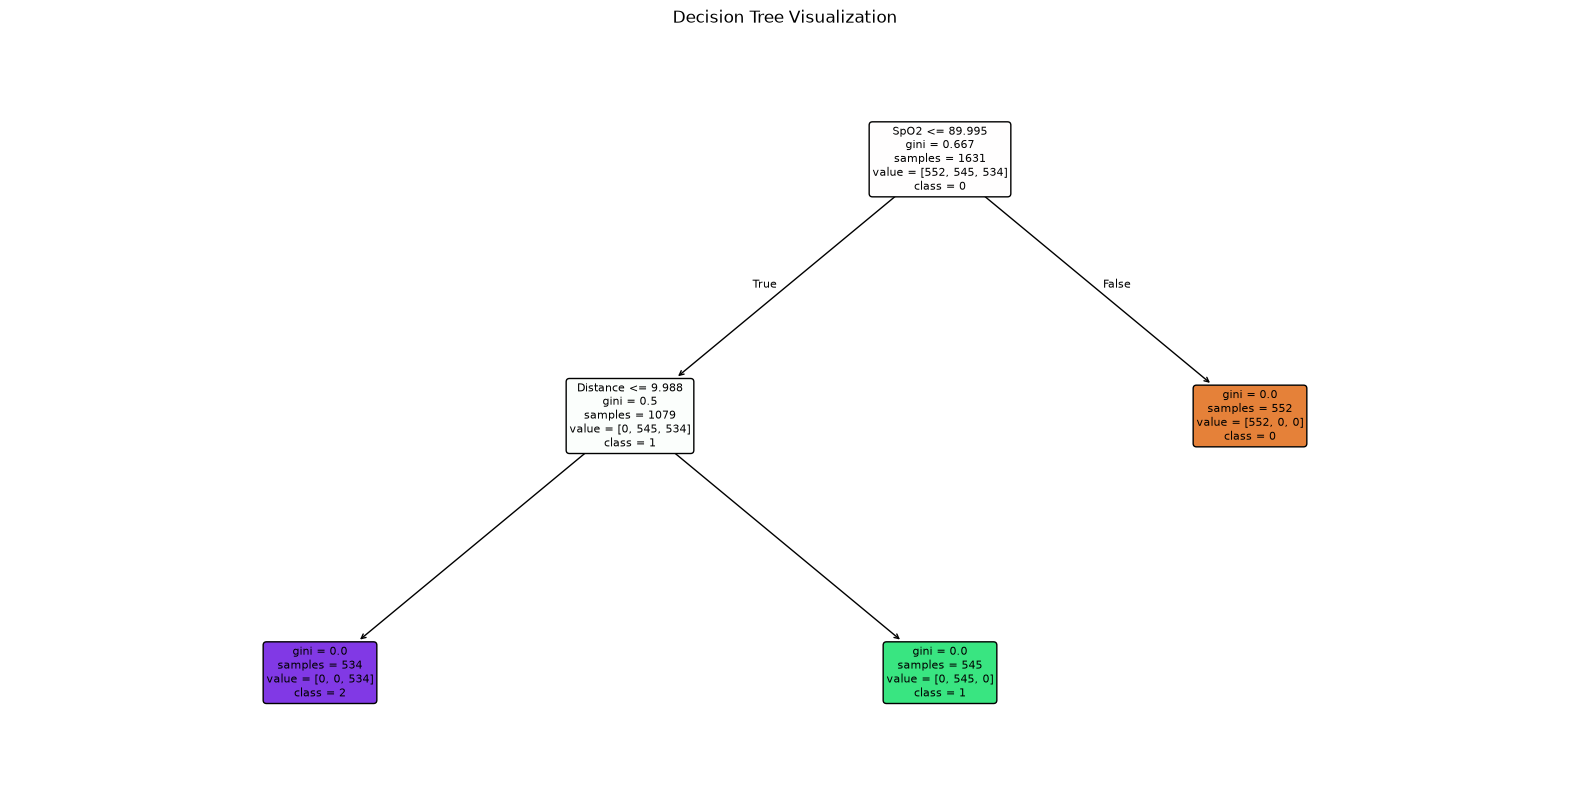

In [24]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=["0", "1", "2"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Visualization")
plt.show()

In [25]:
from sklearn.tree import export_text

tree_rules = export_text(
    dt_model,
    feature_names=list(X.columns)
)

print(tree_rules)

|--- SpO2 <= 89.99
|   |--- Distance <= 9.99
|   |   |--- class: 2
|   |--- Distance >  9.99
|   |   |--- class: 1
|--- SpO2 >  89.99
|   |--- class: 0



In [26]:
rule_pred = np.where(
    df["SpO2"] > 89.99,
    0,
    np.where(df["Distance"] <= 9.99, 2, 1)
)

rule_accuracy = accuracy_score(df["Decision"], rule_pred)

print("Rule-based accuracy:", rule_accuracy * 100, "%")
print("Mismatched rows:", (df["Decision"] != rule_pred).sum())

Rule-based accuracy: 100.0 %
Mismatched rows: 0


In [27]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print(
    "Random Forest Accuracy:",
    accuracy_score(y_test, rf_pred) * 100,
    "%"
)

Random Forest Accuracy: 100.0 %


In [28]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

svm_model = make_pipeline(
    StandardScaler(),
    SVC()
)

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)

print(
    "SVM Accuracy:",
    accuracy_score(y_test, svm_pred) * 100,
    "%"
)

SVM Accuracy: 100.0 %
